In [1]:
!pip install ipython-sql

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 16.5 MB/s  0:00:00


In [2]:
%load_ext sql
%sql sqlite:///retail_sales.db

In [3]:
%%sql

CREATE TABLE Customers (
    customer_id INTEGER PRIMARY KEY,
    customer_name TEXT,
    city TEXT
);

 * sqlite:///retail_sales.db
Done.


[]

In [4]:
%%sql

CREATE TABLE Products (
    product_id INTEGER PRIMARY KEY,
    product_name TEXT,
    category TEXT,
    price REAL
);

 * sqlite:///retail_sales.db
Done.


[]

In [5]:
%%sql

CREATE TABLE Orders (
    order_id INTEGER PRIMARY KEY,
    customer_id INTEGER,
    product_id INTEGER,
    quantity INTEGER,
    order_date TEXT,
    FOREIGN KEY (customer_id) REFERENCES Customers(customer_id),
    FOREIGN KEY (product_id) REFERENCES Products(product_id)
);

 * sqlite:///retail_sales.db
Done.


[]

In [6]:
%%sql

INSERT INTO Customers VALUES
(1, 'Aarav Sharma', 'Mumbai'),
(2, 'Priya Patel', 'Pune'),
(3, 'Rohan Mehta', 'Mumbai'),
(4, 'Sneha Joshi', 'Nashik'),
(5, 'Arjun Desai', 'Thane'),
(6, 'Isha Shah', 'Mumbai'),
(7, 'Kabir Singh', 'Pune'),
(8, 'Ananya Rao', 'Thane'),
(9, 'Vivaan Gupta', 'Mumbai'),
(10, 'Diya Nair', 'Nashik'),
(11, 'Rahul Verma', 'Pune'),
(12, 'Meera Kulkarni', 'Mumbai');

 * sqlite:///retail_sales.db
12 rows affected.


[]

In [7]:
%%sql

INSERT INTO Products VALUES
(101, 'Laptop', 'Electronics', 55000),
(102, 'Mouse', 'Electronics', 800),
(103, 'Keyboard', 'Electronics', 1500),
(104, 'Headphones', 'Electronics', 2500),
(105, 'Notebook', 'Stationery', 100),
(106, 'Pen Set', 'Stationery', 250),
(107, 'Office Chair', 'Furniture', 7500),
(108, 'Study Table', 'Furniture', 12000),
(109, 'Water Bottle', 'Accessories', 500),
(110, 'Backpack', 'Accessories', 1800);

 * sqlite:///retail_sales.db
10 rows affected.


[]

In [8]:
%%sql

INSERT INTO Orders VALUES
(1001, 1, 101, 1, '2025-01-05'),
(1002, 2, 102, 2, '2025-01-10'),
(1003, 3, 105, 5, '2025-01-15'),
(1004, 4, 107, 1, '2025-01-20'),
(1005, 5, 104, 2, '2025-02-03'),
(1006, 6, 103, 1, '2025-02-08'),
(1007, 7, 108, 1, '2025-02-14'),
(1008, 8, 110, 2, '2025-02-20'),
(1009, 9, 101, 1, '2025-03-02'),
(1010, 10, 106, 4, '2025-03-07'),
(1011, 11, 109, 3, '2025-03-12'),
(1012, 12, 102, 5, '2025-03-18'),
(1013, 1, 104, 1, '2025-04-04'),
(1014, 2, 107, 2, '2025-04-09'),
(1015, 3, 103, 3, '2025-04-15');

 * sqlite:///retail_sales.db
15 rows affected.


[]

In [19]:
%config SqlMagic.style = '_DEPRECATED_DEFAULT'

In [20]:
%%sql

SELECT * FROM Customers;

 * sqlite:///retail_sales.db
Done.


customer_id,customer_name,city
1,Aarav Sharma,Mumbai
2,Priya Patel,Pune
3,Rohan Mehta,Mumbai
4,Sneha Joshi,Nashik
5,Arjun Desai,Thane
6,Isha Shah,Mumbai
7,Kabir Singh,Pune
8,Ananya Rao,Thane
9,Vivaan Gupta,Mumbai
10,Diya Nair,Nashik


In [21]:
%%sql

SELECT * FROM Products;

 * sqlite:///retail_sales.db
Done.


product_id,product_name,category,price
101,Laptop,Electronics,55000.0
102,Mouse,Electronics,800.0
103,Keyboard,Electronics,1500.0
104,Headphones,Electronics,2500.0
105,Notebook,Stationery,100.0
106,Pen Set,Stationery,250.0
107,Office Chair,Furniture,7500.0
108,Study Table,Furniture,12000.0
109,Water Bottle,Accessories,500.0
110,Backpack,Accessories,1800.0


In [22]:
%%sql

SELECT * FROM Orders;

 * sqlite:///retail_sales.db
Done.


order_id,customer_id,product_id,quantity,order_date
1001,1,101,1,2025-01-05
1002,2,102,2,2025-01-10
1003,3,105,5,2025-01-15
1004,4,107,1,2025-01-20
1005,5,104,2,2025-02-03
1006,6,103,1,2025-02-08
1007,7,108,1,2025-02-14
1008,8,110,2,2025-02-20
1009,9,101,1,2025-03-02
1010,10,106,4,2025-03-07


In [23]:
%%sql

SELECT
    Orders.order_id,
    Customers.customer_name,
    Customers.city,
    Products.product_name,
    Products.category,
    Products.price,
    Orders.quantity,
    Products.price * Orders.quantity AS revenue,
    Orders.order_date

FROM Orders

INNER JOIN Customers
ON Orders.customer_id = Customers.customer_id

INNER JOIN Products
ON Orders.product_id = Products.product_id;

 * sqlite:///retail_sales.db
Done.


order_id,customer_name,city,product_name,category,price,quantity,revenue,order_date
1001,Aarav Sharma,Mumbai,Laptop,Electronics,55000.0,1,55000.0,2025-01-05
1002,Priya Patel,Pune,Mouse,Electronics,800.0,2,1600.0,2025-01-10
1003,Rohan Mehta,Mumbai,Notebook,Stationery,100.0,5,500.0,2025-01-15
1004,Sneha Joshi,Nashik,Office Chair,Furniture,7500.0,1,7500.0,2025-01-20
1005,Arjun Desai,Thane,Headphones,Electronics,2500.0,2,5000.0,2025-02-03
1006,Isha Shah,Mumbai,Keyboard,Electronics,1500.0,1,1500.0,2025-02-08
1007,Kabir Singh,Pune,Study Table,Furniture,12000.0,1,12000.0,2025-02-14
1008,Ananya Rao,Thane,Backpack,Accessories,1800.0,2,3600.0,2025-02-20
1009,Vivaan Gupta,Mumbai,Laptop,Electronics,55000.0,1,55000.0,2025-03-02
1010,Diya Nair,Nashik,Pen Set,Stationery,250.0,4,1000.0,2025-03-07


In [24]:
%%sql

SELECT
    SUM(Products.price * Orders.quantity) AS total_revenue

FROM Orders

INNER JOIN Products
ON Orders.product_id = Products.product_id;

 * sqlite:///retail_sales.db
Done.


total_revenue
170200.0


In [25]:
%%sql

SELECT
    Products.product_name,
    SUM(Orders.quantity) AS total_quantity

FROM Orders

INNER JOIN Products
ON Orders.product_id = Products.product_id

GROUP BY Products.product_name

ORDER BY total_quantity DESC;

 * sqlite:///retail_sales.db
Done.


product_name,total_quantity
Mouse,7
Notebook,5
Pen Set,4
Keyboard,4
Water Bottle,3
Office Chair,3
Headphones,3
Laptop,2
Backpack,2
Study Table,1


In [26]:
%%sql

SELECT
    Products.category,
    SUM(Products.price * Orders.quantity) AS total_revenue

FROM Orders

INNER JOIN Products
ON Orders.product_id = Products.product_id

GROUP BY Products.category

ORDER BY total_revenue DESC;

 * sqlite:///retail_sales.db
Done.


category,total_revenue
Electronics,129100.0
Furniture,34500.0
Accessories,5100.0
Stationery,1500.0


In [27]:
%%sql

SELECT
    Customers.customer_name,
    Customers.city,
    SUM(Products.price * Orders.quantity) AS total_spent

FROM Orders

INNER JOIN Customers
ON Orders.customer_id = Customers.customer_id

INNER JOIN Products
ON Orders.product_id = Products.product_id

GROUP BY Customers.customer_id

ORDER BY total_spent DESC;

 * sqlite:///retail_sales.db
Done.


customer_name,city,total_spent
Aarav Sharma,Mumbai,57500.0
Vivaan Gupta,Mumbai,55000.0
Priya Patel,Pune,16600.0
Kabir Singh,Pune,12000.0
Sneha Joshi,Nashik,7500.0
Arjun Desai,Thane,5000.0
Rohan Mehta,Mumbai,5000.0
Meera Kulkarni,Mumbai,4000.0
Ananya Rao,Thane,3600.0
Rahul Verma,Pune,1500.0


In [28]:
%%sql

SELECT
    AVG(order_total) AS average_order_value

FROM (
    SELECT
        Orders.order_id,
        SUM(Products.price * Orders.quantity) AS order_total

    FROM Orders

    INNER JOIN Products
    ON Orders.product_id = Products.product_id

    GROUP BY Orders.order_id
);

 * sqlite:///retail_sales.db
Done.


average_order_value
11346.666666666666


In [29]:
import pandas as pd
import matplotlib.pyplot as plt

In [31]:
import sqlite3

conn = sqlite3.connect("retail_sales.db")

print("Database connected successfully!")

Database connected successfully!


In [32]:
category_sales = pd.read_sql_query("""
SELECT
    Products.category,
    SUM(Products.price * Orders.quantity) AS total_revenue
FROM Orders
INNER JOIN Products
ON Orders.product_id = Products.product_id
GROUP BY Products.category
ORDER BY total_revenue DESC;
""", conn)

display(category_sales)

,category,total_revenue
0,Electronics,129100.0
1,Furniture,34500.0
2,Accessories,5100.0
3,Stationery,1500.0


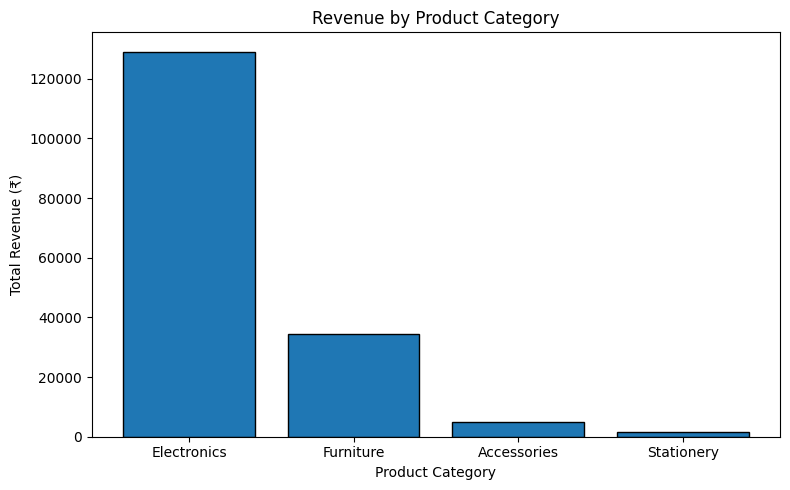

In [33]:
plt.figure(figsize=(8, 5))

plt.bar(
    category_sales["category"],
    category_sales["total_revenue"],
    edgecolor="black"
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue (₹)")

plt.tight_layout()
plt.show()

In [34]:
monthly_sales = pd.read_sql_query("""
SELECT
    strftime('%Y-%m', order_date) AS month,
    SUM(Products.price * Orders.quantity) AS revenue
FROM Orders
INNER JOIN Products
ON Orders.product_id = Products.product_id
GROUP BY month
ORDER BY month;
""", conn)

display(monthly_sales)

,month,revenue
0,2025-01,64600.0
1,2025-02,22100.0
2,2025-03,61500.0
3,2025-04,22000.0


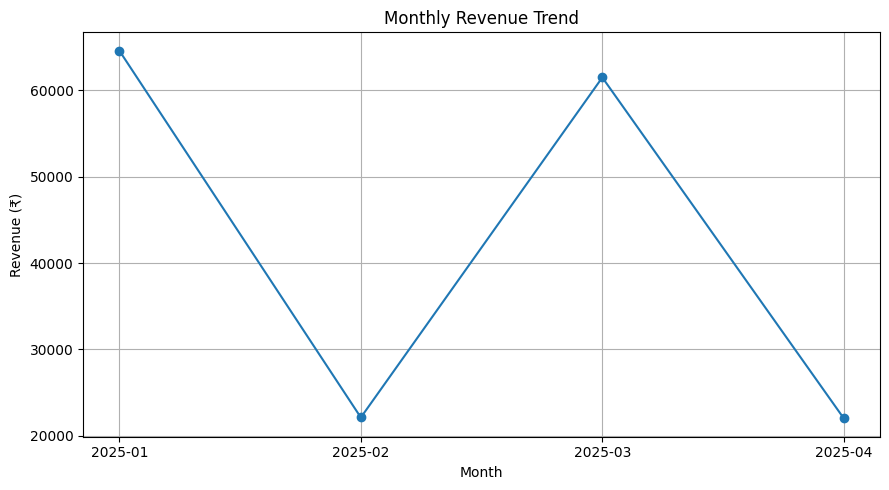

In [35]:
plt.figure(figsize=(9, 5))

plt.plot(
    monthly_sales["month"],
    monthly_sales["revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.grid(True)

plt.tight_layout()
plt.show()

In [36]:
# Total revenue
total_revenue = pd.read_sql_query("""
SELECT SUM(Products.price * Orders.quantity) AS revenue
FROM Orders
JOIN Products
ON Orders.product_id = Products.product_id
""", conn)

# Best-selling product
top_product = pd.read_sql_query("""
SELECT Products.product_name,
       SUM(Orders.quantity) AS quantity_sold
FROM Orders
JOIN Products
ON Orders.product_id = Products.product_id
GROUP BY Products.product_id
ORDER BY quantity_sold DESC
LIMIT 1
""", conn)

# Highest revenue category
best_category = category_sales.iloc[0]

# Best sales month
best_month = monthly_sales.loc[
    monthly_sales["revenue"].idxmax()
]

# Display insights
print("========== BUSINESS INSIGHTS ==========")

print("Total Revenue: ₹", round(total_revenue.iloc[0, 0], 2))

print("Best Selling Product:", top_product.iloc[0]["product_name"])

print("Highest Revenue Category:", best_category["category"])

print("Best Sales Month:", best_month["month"])

print("Monthly Revenue:", round(best_month["revenue"], 2))

========== BUSINESS INSIGHTS ==========
Total Revenue: ₹ 170200.0
Best Selling Product: Mouse
Highest Revenue Category: Electronics
Best Sales Month: 2025-01
Monthly Revenue: 64600.0
